# 🛒 Customer Analytics: What Really Drives a Purchase?

| | |
|---|---|
| **Data** | `Customer_Analytics_Data-LMS.csv`: 500 customers, 15 columns |
| **Question** | What is linked to a customer buying (`Purchased = Yes`)? |
| **Answer** | Online users buy **53.6%** of the time vs **40.3%** for offline users (p = 0.0039) |

---
## Project Overview

Hello everyone. Every store wants to know why some customers buy and others do not. I studied 500 customers, with 15 facts about each one, to find out what really predicts a purchase. Most things did not matter. But one thing did.

---
## Step 1 — Load and Understand the Data

First, the data. It has 500 customers and 15 columns, with no missing values and no repeated rows. 46.6% of customers made a purchase, so we have a good mix of buyers and non-buyers to compare.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind

df = pd.read_csv("Customer_Analytics_Data - LMS.csv")
print("Loaded The Data")

Loaded The Data


In [3]:
print(df.head())
print()
df.info()

   CustomerID  Gender  Age Region  Income Product_Category  Purchase_Amount  \
0       10001    Male   38  North   22717           Sports           936.74   
1       10002  Female   49  North   79676         Clothing          1055.41   
2       10003    Male   40   West   47952             Home          1003.25   
3       10004    Male   50  South  106444           Sports          1350.39   
4       10005    Male   20  South   62460           Sports           322.32   

  Purchased  Customer_Score  Tenure_Years  Visits_Per_Month Discount_Used  \
0        No              38             8                13           Yes   
1        No              15             7                 9           Yes   
2       Yes              63             3                 4           Yes   
3        No              21             0                 5           Yes   
4        No              99             0                11           Yes   

  Online_User Satisfaction_Level Returned_Product  
0         

In [4]:
print(df.describe().round(2))
print(f"\nDataset shape: {df.shape}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nDuplicate rows: {df.duplicated().sum()}   |   CustomerID unique: {df['CustomerID'].is_unique}")

       CustomerID     Age     Income  Purchase_Amount  Customer_Score  \
count      500.00  500.00     500.00           500.00           500.0   
mean     10250.50   40.73   70611.06          1030.13            50.0   
std        144.48   13.28   28024.67           559.15            27.8   
min      10001.00   18.00   20060.00            56.28             1.0   
25%      10125.75   29.00   47839.00           529.46            27.0   
50%      10250.50   41.00   71066.00          1058.24            48.0   
75%      10375.25   52.00   95244.00          1488.04            73.0   
max      10500.00   64.00  119804.00          1998.86           100.0   

       Tenure_Years  Visits_Per_Month  
count        500.00            500.00  
mean           5.01             10.56  
std            3.20              5.92  
min            0.00              1.00  
25%            2.00              5.00  
50%            5.00             10.00  
75%            8.00             16.00  
max           10.00   

In [5]:
# Quick answers to the worksheet's observation questions, computed rather than eyeballed
num_cols = df.select_dtypes("number").columns.drop("CustomerID").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"1. Size .............. {df.shape[0]} rows x {df.shape[1]} columns")
print(f"2. Missing values .... {'YES' if df.isnull().any().any() else 'NO'}")
print(f"3. Data types ........ {df.dtypes.astype(str).value_counts().to_dict()}")
print(f"4. Age range ......... {df['Age'].min()} to {df['Age'].max()}")
print(f"5. Average income .... {df['Income'].mean():,.2f}")
print(f"\nNumeric  ({len(num_cols)}): {num_cols}")
print(f"Categorical ({len(cat_cols)}): {cat_cols}")
print(f"\nOverall purchase rate: {(df['Purchased']=='Yes').mean():.1%}")

1. Size .............. 500 rows x 15 columns
2. Missing values .... NO
3. Data types ........ {'object': 8, 'int64': 6, 'float64': 1}
4. Age range ......... 18 to 64
5. Average income .... 70,611.06

Numeric  (6): ['Age', 'Income', 'Purchase_Amount', 'Customer_Score', 'Tenure_Years', 'Visits_Per_Month']
Categorical (8): ['Gender', 'Region', 'Product_Category', 'Purchased', 'Discount_Used', 'Online_User', 'Satisfaction_Level', 'Returned_Product']

Overall purchase rate: 46.6%


> 📝 **Observation answers (not read aloud)**

| Question | Answer |
|---|---|
| Rows × columns | 500 × 15 |
| Missing values? | No |
| Data types | 7 numeric (`CustomerID` is just an ID), 8 text columns |
| Age range | 18 to 64 |
| Average income | about 70,611 |

Also: no repeated rows, and `CustomerID` is unique.

---
## Step 2 — Automated EDA Report

Next, one line of code builds a full report with charts, correlations, and data-quality alerts. It saves hours of work, but it is only a map. The real work is reading it.

> 📝 `pandas-profiling` is now called `ydata-profiling`. The code tries the new name first. The report is saved as `customer_eda_report.html`.

In [7]:
try:
    from ydata_profiling import ProfileReport          # modern name
except ImportError:
    from pandas_profiling import ProfileReport         # legacy name

profile = ProfileReport(df, title="Customer Analytics Dataset", explorative=True, progress_bar=False)
profile.to_file("customer_eda_report.html")
print("Report generated! Open customer_eda_report.html in your browser.")

/tmp/ipykernel_2645/3973050266.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport          # modern name
100%|██████████| 15/15 [00:00<00:00, 16.43it/s]


Report generated! Open customer_eda_report.html in your browser.


In [8]:
# Pull the report's own automatic alerts so our write-up cites what the tool actually flagged
desc = profile.get_description()
alerts = desc.alerts
print(f"The profiler raised {len(alerts)} alerts:\n")
for a in alerts:
    print(" •", str(a).replace("[", "").replace("]", "")[:140])

The profiler raised 3 alerts:

 • CustomerID is uniformly distributed
 • CustomerID has unique values
 • Tenure_Years has 49 (9.8%) zeros


> 📝 **Step 2 checklist:** code ran with no errors ☑ · `customer_eda_report.html` created ☑ · open it and check the sections: Overview, Variables, Interactions, Correlations, Missing values, Sample ☑

---
## Step 3 — Explore the Report and Find Key Findings

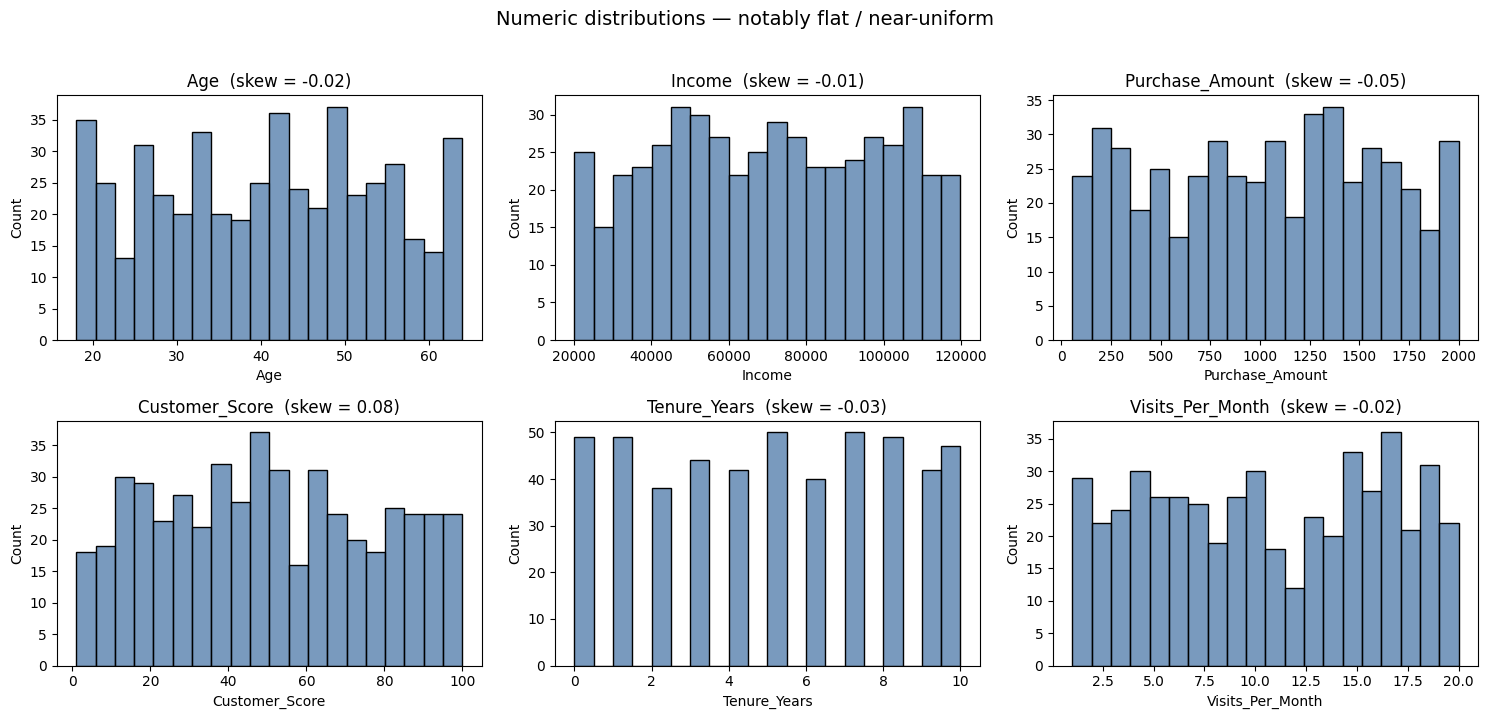

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), ["Age", "Income", "Purchase_Amount", "Customer_Score", "Tenure_Years", "Visits_Per_Month"]):
    sns.histplot(df[col], bins=20, ax=ax, color="#4C78A8")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
plt.suptitle("Numeric distributions — notably flat / near-uniform", y=1.02, fontsize=14)
plt.tight_layout();
plt.savefig("charts/Exploring_The_Data.png", dpi=300, bbox_inches="tight")
plt.show()

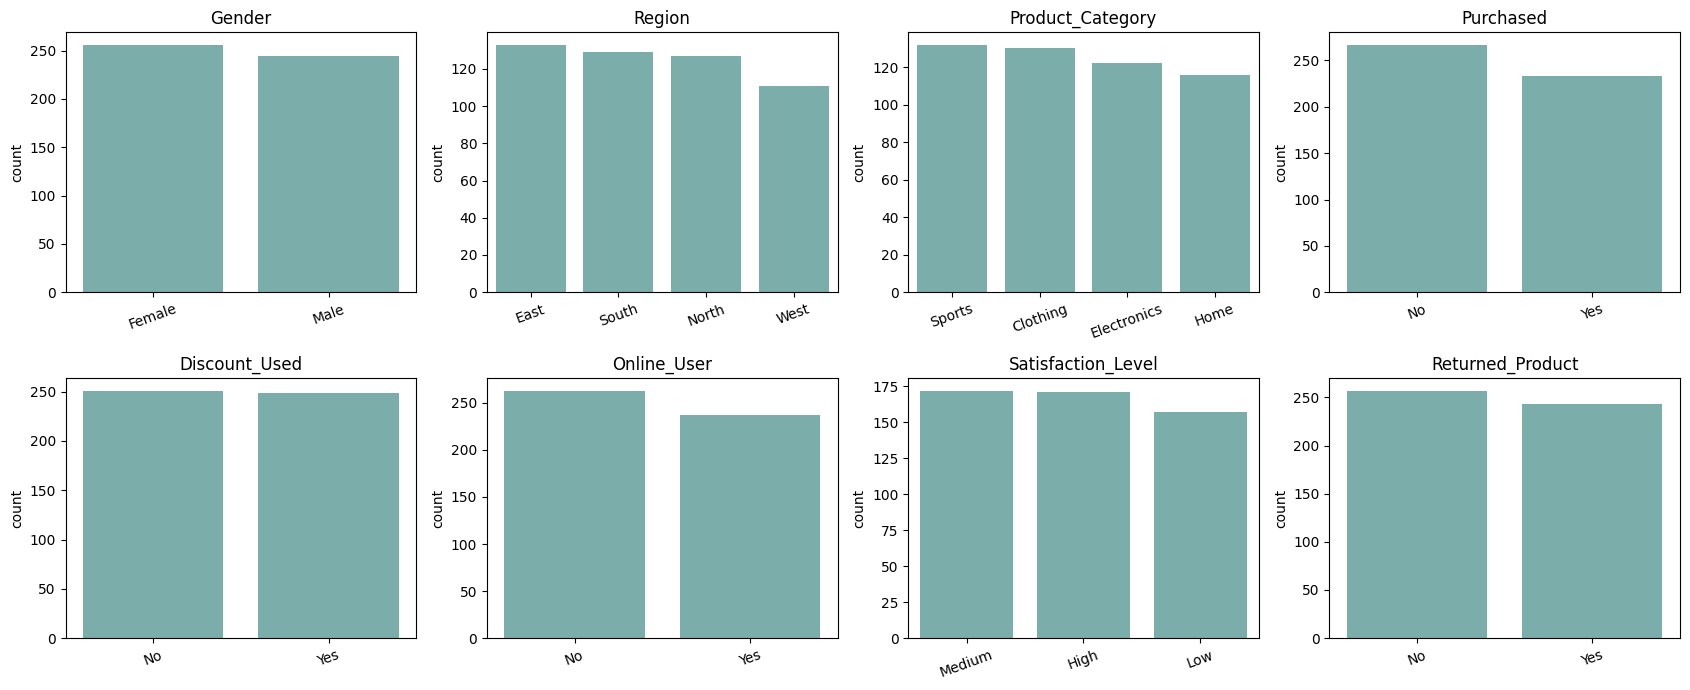

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color="#72B7B2")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout();
plt.savefig("charts/Sub-Plot.png", dpi=300, bbox_inches="tight")
plt.show()

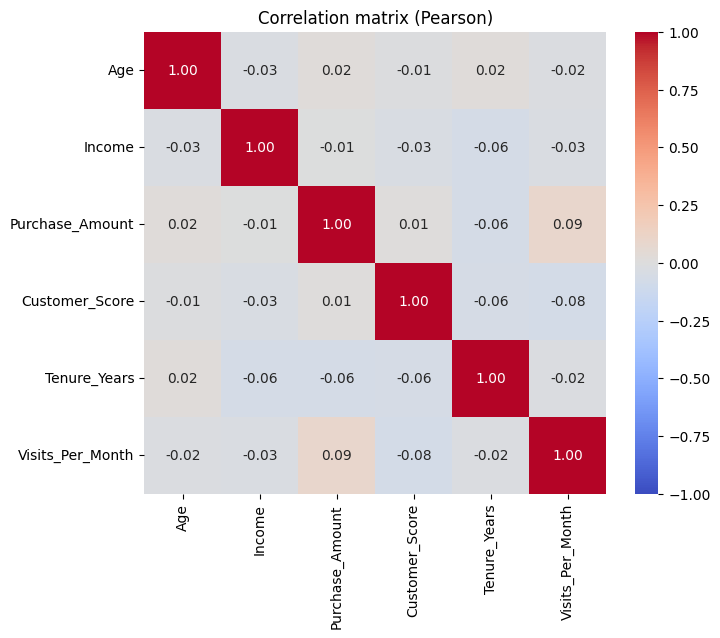

Strongest correlation: Visits_Per_Month & Purchase_Amount   r = +0.091   (p = 0.042)


In [13]:
corr = df[num_cols].corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (Pearson)");
plt.savefig("charts/Correlation_Matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Strongest pair (excluding the diagonal)
pairs = corr.where(~np.eye(len(corr), dtype=bool)).abs().unstack().dropna().sort_values(ascending=False)
top = pairs.index[0]
r = corr.loc[top]; p_r = stats.pearsonr(df[top[0]], df[top[1]])[1]
print(f"Strongest correlation: {top[0]} & {top[1]}   r = {r:+.3f}   (p = {p_r:.3f})")

In [14]:
# Data-quality sanity checks the worksheet asks about (Finding 4 & 5)
print("Unique values per column (cardinality):")
print(df.nunique().sort_values(ascending=False).to_string())

print("\nPurchase_Amount recorded for customers who did NOT purchase:")
print(df.groupby("Purchased")["Purchase_Amount"].agg(["count", "mean", "min", "max"]).round(2))

Unique values per column (cardinality):
CustomerID            500
Purchase_Amount       498
Income                498
Customer_Score         98
Age                    47
Visits_Per_Month       20
Tenure_Years           11
Region                  4
Product_Category        4
Satisfaction_Level      3
Gender                  2
Purchased               2
Discount_Used           2
Online_User             2
Returned_Product        2

Purchase_Amount recorded for customers who did NOT purchase:
           count     mean    min      max
Purchased                                
No           267  1039.08  64.75  1998.86
Yes          233  1019.87  56.28  1984.03


### Key Findings

What stood out? First, the data is clean. Second, the numbers are spread evenly and barely connect to each other. The strongest link, between visits per month and purchase amount, is only 0.09, which is almost nothing. Third, purchase amounts are recorded even for people who did not buy, so I would ask the data team about that. Since no number predicts buying, I checked the yes-or-no columns next.

> 📝 **Findings (not read aloud)**
1. **Overview:** 500 × 15, 0 missing, 0 repeated rows, 46.6% purchased.
2. **Most interesting variable:** `Purchase_Amount`. It is spread evenly from about $56 to $1,999, and it is filled in even for non-buyers (average about $1,039 for "No" vs $1,020 for "Yes").
3. **Strongest correlation:** `Visits_Per_Month` and `Purchase_Amount`, r ≈ +0.09 (p ≈ 0.04). Weak: under 1% of the variation, and not safe from chance after checking 15 pairs.
4. **Data quality:** only 3 profiler alerts: `CustomerID` is unique (it is an ID), and `Tenure_Years` has 49 zeros (new customers, which is fine). The real concern is the amount recorded for non-buyers.
5. **High-cardinality column:** yes, `CustomerID` (500 unique values). It is left out of all tests.

---
## Step 4 — Hypotheses

I used AI to brainstorm three ideas to test. Does shopping online change buying? Does product category? Does using a discount change spending? I picked the first. A business can act on it, because you can invest in online shopping, but you cannot change a customer's age. I still tested the other two.

> 📝 **GenAI prompt used:** "I analyzed a customer dataset (500 customers, 15 variables). The data is clean, 46.6% purchased, and numbers are only weakly correlated (strongest r ≈ 0.09). Give me 3 testable hypotheses with null and alternative." *(Replace with your own chat if your instructor asks for it.)*

| # | Null hypothesis (H₀) | Alternative (Hₐ) | Test |
|---|---|---|---|
| **1** | `Online_User` and `Purchased` are independent | Purchase rate differs online vs offline | Chi-square |
| **2** | `Product_Category` and `Purchased` are independent | Purchase rate differs by category | Chi-square |
| **3** | Discount users and non-users spend the same | Average `Purchase_Amount` differs | Welch t-test |

**Why Hypothesis 1:** (1) the business can act on it; (2) it is about buying itself, not spending; (3) a quick check of every yes/no column pointed to it (next cell).

In [15]:
# Screen every categorical predictor against Purchased (chi-square), as justification for the selection
rows = []
for col in [c for c in cat_cols if c != "Purchased"]:
    ct = pd.crosstab(df[col], df["Purchased"])
    chi2_, p_, dof_, _ = chi2_contingency(ct)
    rate = (ct["Yes"] / ct.sum(axis=1)).round(3).to_dict()
    rows.append({"Variable": col, "chi2": round(chi2_, 3), "dof": dof_, "p_value": round(p_, 4), "purchase_rate_by_level": rate})
screen = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
screen

,Variable,chi2,dof,p_value,purchase_rate_by_level
0,Online_User,8.312,1,0.0039,"{'No': 0.403, 'Yes': 0.536}"
1,Returned_Product,3.051,1,0.0807,"{'No': 0.506, 'Yes': 0.424}"
2,Product_Category,5.020,3,0.1703,"{'Clothing': 0.523, 'Electronics': 0.41, 'Home..."
3,Satisfaction_Level,1.066,2,0.5869,"{'High': 0.439, 'Low': 0.465, 'Medium': 0.494}"
4,Gender,0.251,1,0.6160,"{'Female': 0.453, 'Male': 0.48}"
5,Discount_Used,0.007,1,0.9334,"{'No': 0.462, 'Yes': 0.47}"
6,Region,0.079,3,0.9942,"{'East': 0.474, 'North': 0.457, 'South': 0.465..."


In [16]:
# --- Secondary checks: Hypotheses 2 and 3 ---
# H2: Product_Category vs Purchased
ct2 = pd.crosstab(df["Product_Category"], df["Purchased"])
chi2_2, p2, dof2, _ = chi2_contingency(ct2)
print(f"H2  Product_Category vs Purchased : chi2 = {chi2_2:.3f}, dof = {dof2}, p = {p2:.4f}  ->",
      "REJECT H0" if p2 < 0.05 else "FAIL TO REJECT H0")

# H3: Discount_Used vs Purchase_Amount (Welch t-test)
g_yes = df.loc[df["Discount_Used"] == "Yes", "Purchase_Amount"]
g_no  = df.loc[df["Discount_Used"] == "No",  "Purchase_Amount"]
t3, p3 = ttest_ind(g_yes, g_no, equal_var=False)
print(f"H3  Discount_Used vs Purchase_Amount: mean(Yes) = {g_yes.mean():,.0f}, mean(No) = {g_no.mean():,.0f}, "
      f"t = {t3:.3f}, p = {p3:.4f}  ->", "REJECT H0" if p3 < 0.05 else "FAIL TO REJECT H0")

H2  Product_Category vs Purchased : chi2 = 5.020, dof = 3, p = 0.1703  -> FAIL TO REJECT H0
H3  Discount_Used vs Purchase_Amount: mean(Yes) = 1,056, mean(No) = 1,005, t = 1.012, p = 0.3122  -> FAIL TO REJECT H0


---
## Step 5 — The Statistical Test

In [17]:
# Contingency table
contingency = pd.crosstab(df["Online_User"], df["Purchased"])
print("Contingency Table (observed):")
print(contingency)

# Test (scipy default applies Yates' continuity correction for 2x2 tables)
chi2, p_value, dof, expected = chi2_contingency(contingency)
print("\nExpected counts under H0:")
print(pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(1))
print(f"\nAssumption check -> smallest expected count = {expected.min():.1f} (needs to be >= 5): {'OK' if expected.min() >= 5 else 'VIOLATED'}")

print("\nChi-Square Test Results:")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

alpha = 0.05
if p_value < alpha:
    print(f"REJECT H0 (p={p_value:.4f} < 0.05): Variables ARE related.")
else:
    print(f"FAIL TO REJECT H0 (p={p_value:.4f} > 0.05): No significant relationship.")

Contingency Table (observed):
Purchased     No  Yes
Online_User          
No           157  106
Yes          110  127

Expected counts under H0:
Purchased       No    Yes
Online_User              
No           140.4  122.6
Yes          126.6  110.4

Assumption check -> smallest expected count = 110.4 (needs to be >= 5): OK

Chi-Square Test Results:
Chi-Square Statistic: 8.3123
P-value: 0.0039
Degrees of Freedom: 1
REJECT H0 (p=0.0039 < 0.05): Variables ARE related.


In [20]:
# --- Is the result robust, and how big is the effect? ---
from statsmodels.stats.proportion import proportion_confint

chi2_nc, p_nc, _, _ = chi2_contingency(contingency, correction=False)
odds_ratio, p_fisher = stats.fisher_exact(contingency)
cramers_v = np.sqrt(chi2_nc / len(df))                      # = phi for a 2x2 table

rate = (contingency["Yes"] / contingency.sum(axis=1))
n    = contingency.sum(axis=1)
ci   = {k: proportion_confint(contingency.loc[k, "Yes"], n[k], method="wilson") for k in contingency.index}

print(f"Without Yates correction : chi2 = {chi2_nc:.3f}, p = {p_nc:.4f}")
print(f"Fisher's exact test      : p = {p_fisher:.4f}   (odds ratio = {odds_ratio:.2f})")
print(f"Effect size (Cramer's V) : {cramers_v:.3f}  -> small-to-moderate")
print()
for k in contingency.index:
    print(f"Online_User = {k:<3}: purchase rate = {rate[k]:.1%}   95% CI [{ci[k][0]:.1%}, {ci[k][1]:.1%}]   (n = {n[k]})")
print(f"\nDifference: {rate['Yes'] - rate['No']:+.1%} points   |   Relative lift: x{rate['Yes'] / rate['No']:.2f}")

# Multiple-comparison guard: we screened 7 categorical variables, so use Bonferroni
n_tests = len(screen)
print(f"\nBonferroni threshold for {n_tests} screened variables: {0.05 / n_tests:.4f}  ->  "
      f"Online_User p = {p_value:.4f} {'still significant' if p_value < 0.05 / n_tests else 'NOT significant'}")

Without Yates correction : chi2 = 8.838, p = 0.0030
Fisher's exact test      : p = 0.0031   (odds ratio = 1.71)
Effect size (Cramer's V) : 0.133  -> small-to-moderate

Online_User = No : purchase rate = 40.3%   95% CI [34.6%, 46.3%]   (n = 263)
Online_User = Yes: purchase rate = 53.6%   95% CI [47.2%, 59.8%]   (n = 237)

Difference: +13.3% points   |   Relative lift: x1.33

Bonferroni threshold for 7 screened variables: 0.0071  ->  Online_User p = 0.0039 still significant


In [23]:
# Does the effect survive after controlling for everything else? (logistic regression)
import statsmodels.formula.api as smf

df["y"] = (df["Purchased"] == "Yes").astype(int)
logit = smf.logit(
    "y ~ C(Online_User) + Age + Income + Visits_Per_Month + Tenure_Years + Customer_Score"
    " + C(Gender) + C(Region) + C(Product_Category) + C(Discount_Used) + C(Satisfaction_Level) + C(Returned_Product)",
    data=df).fit(disp=0)
coef = "C(Online_User)[T.Yes]"
or_adj = np.exp(logit.params[coef]); lo, hi = np.exp(logit.conf_int().loc[coef])
print(f"Adjusted odds ratio for Online_User = Yes: {or_adj:.2f}  (95% CI {lo:.2f} - {hi:.2f}),  p = {logit.pvalues[coef]:.4f}")
print("All other predictors significant at 5%? ->",
      [k for k, v in logit.pvalues.items() if v < 0.05 and k not in ("Intercept", coef)] or "None")

Adjusted odds ratio for Online_User = Yes: 1.73  (95% CI 1.21 - 2.49),  p = 0.0029
All other predictors significant at 5%? -> None


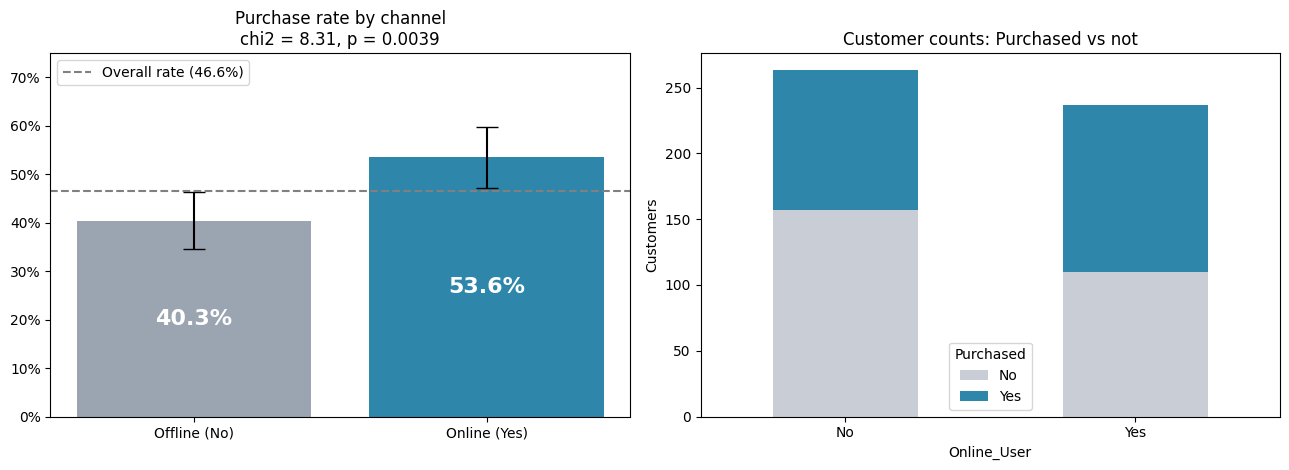

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) Purchase rate with 95% CI
labels = ["Offline (No)", "Online (Yes)"]; vals = [rate["No"], rate["Yes"]]
errs = [[rate[k] - ci[k][0] for k in ["No", "Yes"]], [ci[k][1] - rate[k] for k in ["No", "Yes"]]]
bars = axes[0].bar(labels, vals, yerr=errs, capsize=8, color=["#9AA5B1", "#2E86AB"])
axes[0].axhline((df["Purchased"] == "Yes").mean(), ls="--", color="grey", label="Overall rate (46.6%)")
for b, v in zip(bars, vals):
    axes[0].text(b.get_x() + b.get_width() / 2, v / 2, f"{v:.1%}", ha="center", va="center", fontweight="bold", fontsize=16, color="white")
axes[0].set_ylim(0, 0.75); axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_title(f"Purchase rate by channel\nchi2 = {chi2:.2f}, p = {p_value:.4f}"); axes[0].legend(loc="upper left")

# (b) Counts
contingency.plot(kind="bar", stacked=True, ax=axes[1], color=["#C9CED6", "#2E86AB"], rot=0)
axes[1].grid(axis="x", visible=False); axes[1].set_title("Customer counts: Purchased vs not"); axes[1].set_xlabel("Online_User"); axes[1].set_ylabel("Customers")
plt.tight_layout(); plt.savefig("online_vs_purchase.png", bbox_inches="tight");
plt.savefig("charts/online_vs_purchase.png", dpi=300, bbox_inches="tight")
plt.show()

Here is the test. 40% of offline customers bought. Among online customers, it was 53.6%. A chi-square test gives a p-value of 0.004. In plain words, if the channel did not matter, we would see a gap this big less than half a percent of the time. So the link is real. It held up in extra checks, including one that adjusts for every other column. Category and discounts showed nothing. One caution: this shows a link, not a cause, and the effect is moderate.

> 📝 **Results (not read aloud)**

| Field | Result |
|---|---|
| Test | Chi-square test of independence |
| H₀ / Hₐ | `Online_User` and `Purchased` are independent / they are linked |
| Test statistic | χ² = 8.3123 (df = 1) |
| P-value | 0.0039 |
| Decision | **Reject H₀** |

**Extra checks:** no continuity correction χ² = 8.84, p = 0.0030 · Fisher's exact p = 0.0031 · passes a Bonferroni correction (threshold 0.0071 for 7 variables) · after adjusting for 11 other variables, odds ratio = 1.73 (95% CI 1.21–2.49, p = 0.003). **Effect size:** Cramér's V ≈ 0.13 (small to moderate).

**Interpretation:** online customers buy 53.6% vs 40.3% offline, a gap of about 13 points. The 95% intervals (≈ 47–60% vs ≈ 35–46%) do not overlap. This is a link, not proof of cause.

**Other hypotheses:** H2 category vs purchase: χ² = 5.02, p = 0.170, no link. H3 discount vs spend: t = 1.01, p = 0.312, no link.

---
## Step 6 — Business Summary

In summary: online customers are about 1.3 times more likely to buy, 53.6% against 40.3%. Age, income, and visits showed no useful link. I recommend three steps. One, run an A/B test that nudges offline customers online. Two, invest in the online experience. Three, ask the data team why non-buyers have purchase amounts.

> 📝 **GenAI prompt used:** "Write a one-paragraph business summary: 500 customers, 15 variables, weak correlations, chi-square χ²(1) = 8.31, p = 0.0039, online 53.6% vs offline 40.3%, plus next steps." **What I changed in the AI draft:** added the 1.3× comparison, used "link" instead of "driver" (no proof of cause), and added the data-quality follow-up.

---
## Step 7 — Wrap-up

To recap: we automated the exploring, used AI to sharpen the questions, and let statistics decide. The answer: for this business, buying happens online. Thank you for watching.

> 📝 **Submission checklist:** EDA report ☑ · key findings ☑ · hypotheses ☑ · test results ☑ · business summary ☑ · all sections filled in ☑. Files: `customer_eda_report.html`, this notebook, `online_vs_purchase.png`. If the worksheet must be PDF/DOCX, use File → Download as.

---
## Reflection Questions

1. **Most valuable insight from the EDA report:** nearly every numeric column is flat and unconnected (|r| < 0.1). That told me to look at the yes/no columns instead.
2. **How helpful was GenAI for hypotheses?** Very helpful for speed and wording. But the data, not the AI, pointed to `Online_User`. My first guesses (category, discounts) did not hold up.
3. **Did the test confirm or contradict the hypotheses?** It confirmed Hypothesis 1 (p = 0.0039) and did not support Hypotheses 2 and 3 (p = 0.17 and 0.31).
4. **What would I improve with more time?** Run an A/B test for cause. Collect more customers (the category gap of 52% vs 41% may be real but too small to prove). Ask about the non-buyer amounts. Try a prediction model and look for effects by region or age.
5. **Tool ratings (1–5):** profiling tool 5 · GenAI for hypotheses 4 · Python for testing 5 · GenAI for summary 4